# Praktikum 1: Klasifikasi Gambar Day vs Night dengan HOG + Neural Network

* **Mata Kuliah**: Pembelajaran Mesin (RTI235004)
* **Topik Modul**: JS15 - Pipeline Machine Learning & Deployment
* **Nama**: Mohammad Al Hafis Hidayatulloh
* **NIM**: 254107023005
* **Kelas**: TI-3G

---

### Deskripsi Praktikum
Pada praktikum ini dibangun *pipeline* Machine Learning lengkap untuk mengklasifikasikan citra pemandangan menjadi **siang (*day*)** atau **malam (*night*)**. Hasil akhir praktikum ini adalah dua **artefak** yang akan dipakai saat *deployment* pada Praktikum 2:

| Artefak | Isi | Kegunaan |
|---|---|---|
| `day_night_model.h5` | Bobot Neural Network hasil training | Melakukan prediksi |
| `scaler.pkl` | Parameter `StandardScaler` (mean & std) | Menormalisasi fitur inferensi **sama persis** dengan training |

Tahapan *pipeline*:
1. **Data Ingestion** – memuat citra dari folder `images/training` dan `images/test`.
2. **Preprocessing** – *resize* ke 256×256 piksel dan *label encoding* (`day` → 1, `night` → 0).
3. **Feature Extraction** – konversi *grayscale* lalu ekstraksi fitur **HOG** (*Histogram of Oriented Gradients*).
4. **Normalisasi** – `StandardScaler` (rata-rata 0, variansi 1).
5. **Modeling** – *feedforward Neural Network* (128 → 64 → 1).
6. **Evaluasi & Ekspor Artefak**.

> **Catatan lingkungan:** Modul asli menggunakan Google Colab + Google Drive. Notebook ini dijalankan secara **lokal**, sehingga langkah `drive.mount()` diganti dengan *path* relatif ke folder `images/` yang berada satu direktori dengan notebook.

### Langkah 1 - Import Library
Mengimpor pustaka untuk pengolahan citra (OpenCV, scikit-image), *machine learning* (scikit-learn), dan *deep learning* (TensorFlow/Keras). *Seed* acak ditetapkan agar hasil eksperimen dapat direproduksi.

In [1]:
import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow Version : {tf.__version__}")
print(f"OpenCV Version     : {cv2.__version__}")

TensorFlow Version : 2.21.0
OpenCV Version     : 4.12.0


### Langkah 2 - Load Dataset
Fungsi `load_dataset` membaca setiap subfolder (nama subfolder = label) dan memuat seluruh citra `.jpg`. OpenCV membaca citra dalam format **BGR**, sehingga dikonversi ke **RGB** agar warna tampil benar saat divisualisasikan.

In [2]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in sorted(p.glob('*')):
        label = folder.name
        for file in sorted(folder.glob('*.jpg')):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "images/training"
test_dir  = "images/test"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing : {len(test_img)}")
for name, data in [('Training', train_img), ('Testing', test_img)]:
    labels = [lbl for _, lbl in data]
    print(f"  {name:8s} -> day: {labels.count('day')}, night: {labels.count('night')}")

Jumlah data training: 240
Jumlah data testing : 160
  Training -> day: 120, night: 120
  Testing  -> day: 80, night: 80


#### Contoh Citra Dataset
Ukuran citra asli bervariasi, sehingga perlu diseragamkan pada tahap *preprocessing*.

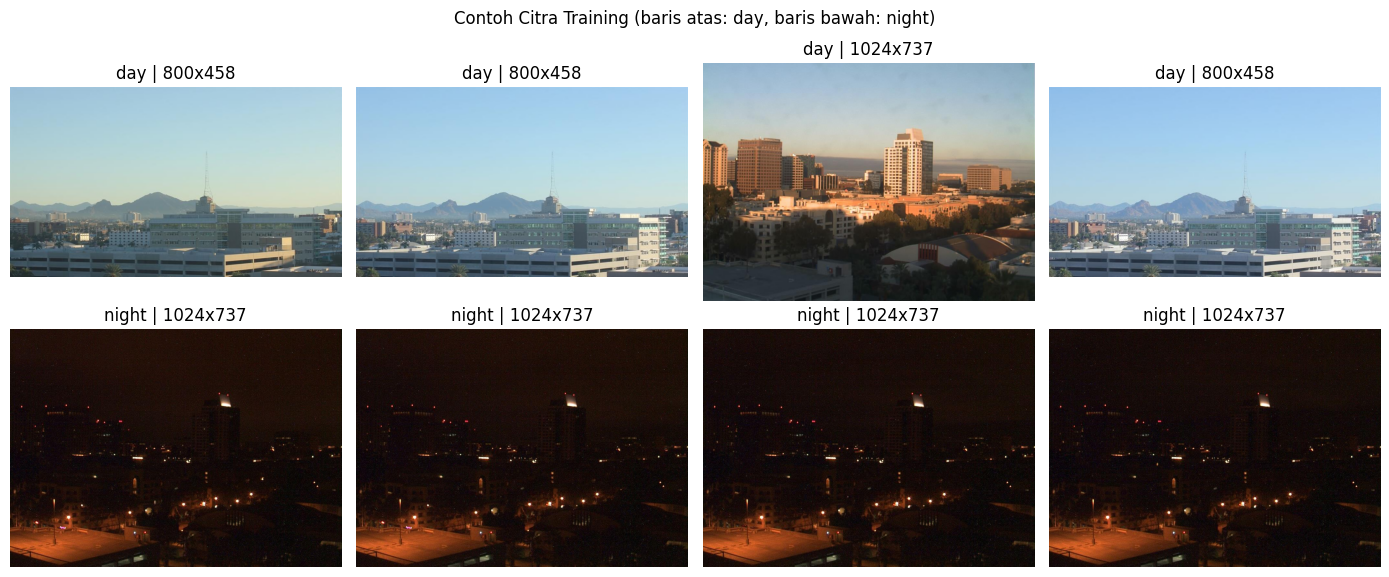

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
days   = [d for d in train_img if d[1] == 'day'][:4]
nights = [d for d in train_img if d[1] == 'night'][:4]
for ax, (img, lbl) in zip(axes.flat, days + nights):
    ax.imshow(img)
    ax.set_title(f"{lbl} | {img.shape[1]}x{img.shape[0]}")
    ax.axis('off')
plt.suptitle("Contoh Citra Training (baris atas: day, baris bawah: night)")
plt.tight_layout()
plt.show()

### Langkah 3 - Preprocessing (Resize & Label Encoding)
* **Resize** ke 256×256 piksel agar setiap citra menghasilkan vektor fitur HOG dengan panjang yang sama.
* **Label encoding**: `day` → `1`, `night` → `0` (klasifikasi biner).

In [4]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

print(f"Ukuran citra setelah resize: {X_train_img[0].shape}")

Ukuran citra setelah resize: (256, 256, 3)


### Langkah 4 - Ekstraksi Fitur HOG (Histogram of Oriented Gradients)
HOG menghitung distribusi arah gradien intensitas pada sel-sel kecil citra, sehingga menangkap informasi **bentuk, tepi, dan tekstur**. Parameter yang digunakan:
* `orientations=9` – 9 *bin* arah gradien (0°–180°).
* `pixels_per_cell=(8,8)` – setiap sel berukuran 8×8 piksel → 32×32 sel.
* `cells_per_block=(2,2)` – normalisasi blok 2×2 sel → 31×31 blok.

Panjang vektor fitur = 31 × 31 blok × (2 × 2 sel) × 9 orientasi = **34.596 fitur** per citra.

In [5]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

print(f"Dimensi fitur training: {X_train_feat.shape}")
print(f"Dimensi fitur testing : {X_test_feat.shape}")

Dimensi fitur training: (240, 34596)
Dimensi fitur testing : (160, 34596)


#### Visualisasi HOG
Gambar HOG menunjukkan arah gradien dominan. Citra siang umumnya memiliki banyak tepi/tekstur yang terlihat jelas, sedangkan citra malam didominasi area gelap yang minim gradien.

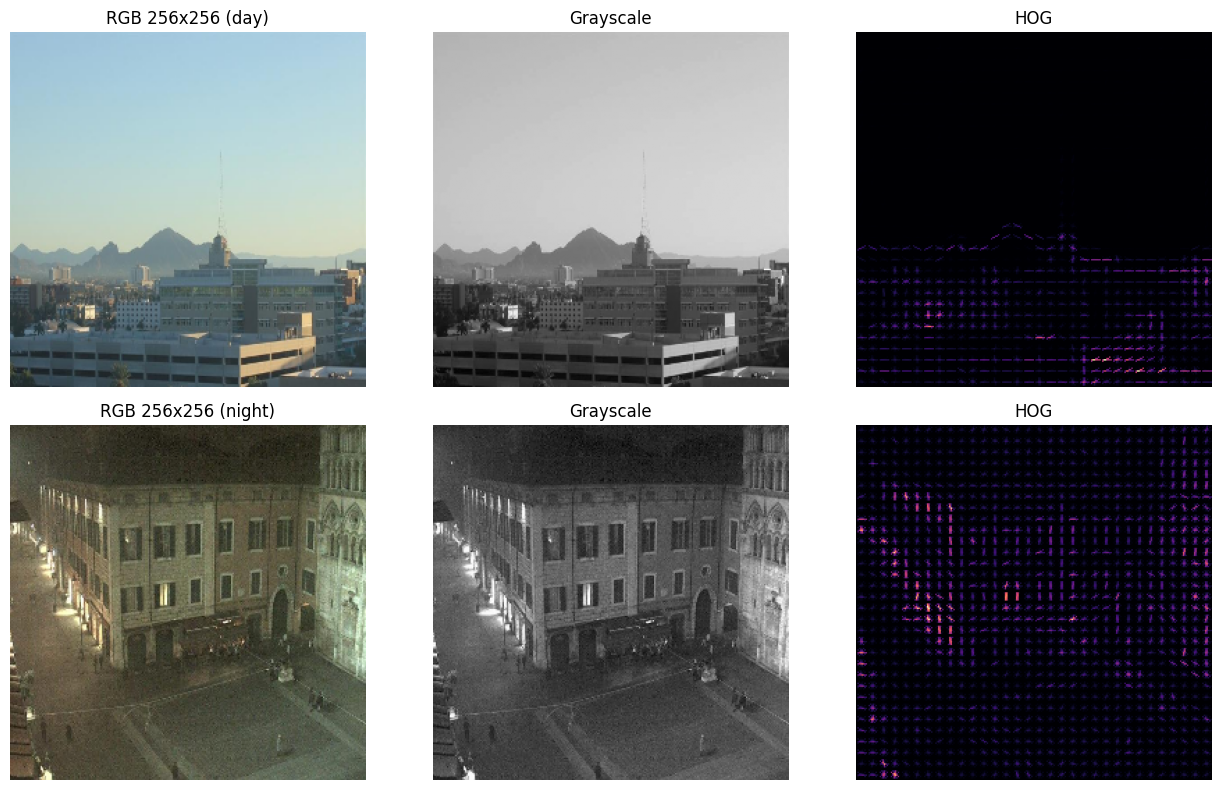

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row, idx in enumerate([0, len(X_train_img) - 1]):
    img = X_train_img[idx]
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, hog_img = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                     cells_per_block=(2, 2), block_norm='L2-Hys', visualize=True)
    lbl = 'day' if y_train[idx] == 1 else 'night'
    axes[row, 0].imshow(img);                axes[row, 0].set_title(f"RGB 256x256 ({lbl})")
    axes[row, 1].imshow(gray, cmap='gray');  axes[row, 1].set_title("Grayscale")
    axes[row, 2].imshow(hog_img, cmap='magma'); axes[row, 2].set_title("HOG")
    for ax in axes[row]:
        ax.axis('off')
plt.tight_layout()
plt.show()

### Langkah 5 - Normalisasi Fitur
`StandardScaler` mempelajari **mean** dan **standar deviasi** dari data training (`fit_transform`), lalu menerapkan parameter yang sama ke data testing (`transform`). Parameter inilah yang nanti disimpan ke `scaler.pkl`.

In [7]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print(f"Mean fitur training setelah scaling : {X_train_scaled.mean():.4f}")
print(f"Std fitur training setelah scaling  : {X_train_scaled.std():.4f}")

Mean fitur training setelah scaling : 0.0000
Std fitur training setelah scaling  : 1.0000


### Langkah 6 - Split Data Training & Validation
Data training dibagi 80% train dan 20% validation untuk memantau *overfitting* selama training.

In [8]:
# Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)
print(f"Train: {X_train.shape[0]} | Validation: {X_val.shape[0]} | Test: {X_test_scaled.shape[0]}")

Train: 192 | Validation: 48 | Test: 160


### Langkah 7 - Konversi Label ke Numpy Array
Keras membutuhkan label dalam bentuk `numpy.ndarray`.

In [9]:
# Convert labels to numpy arrays (required for Keras)
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

### Langkah 8 - Membangun Arsitektur Model Neural Network
Model *Sequential* dengan:
* **Input layer** berukuran sesuai jumlah fitur HOG (34.596).
* **Hidden layer 1**: 128 neuron, aktivasi ReLU.
* **Hidden layer 2**: 64 neuron, aktivasi ReLU.
* **Output layer**: 1 neuron, aktivasi Sigmoid (probabilitas kelas `day`).

Model dikompilasi dengan optimizer **Adam** dan *loss* **binary crossentropy**.

In [10]:
# Build a simple feedforward neural network
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 9 - Training Model
Model dilatih selama 20 *epoch* dengan *batch size* 32.

In [11]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=2
)

Epoch 1/20


6/6 - 1s - 239ms/step - accuracy: 0.7865 - loss: 1.0755 - val_accuracy: 1.0000 - val_loss: 0.0147


Epoch 2/20


6/6 - 0s - 67ms/step - accuracy: 0.9844 - loss: 0.1313 - val_accuracy: 1.0000 - val_loss: 0.0058


Epoch 3/20


6/6 - 0s - 68ms/step - accuracy: 0.9948 - loss: 0.0285 - val_accuracy: 1.0000 - val_loss: 0.0098


... (30 outputs left out)

Epoch 19/20


6/6 - 0s - 63ms/step - accuracy: 1.0000 - loss: 6.2156e-07 - val_accuracy: 0.9792 - val_loss: 0.0255


Epoch 20/20


6/6 - 0s - 62ms/step - accuracy: 1.0000 - loss: 6.0538e-07 - val_accuracy: 0.9792 - val_loss: 0.0255


### Langkah 10 - Evaluasi Model
Menguji performa model pada data testing yang belum pernah dilihat selama training.

In [12]:
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Loss Test    : {test_loss:.4f}")
print(f"Akurasi Test : {test_acc:.4f}")

Loss Test    : 1.3260
Akurasi Test : 0.9000


### Langkah 11 - Prediksi, Laporan Klasifikasi, dan Visualisasi

In [13]:
# Generate classification report and confusion matrix
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

print(classification_report(y_test, y_pred, target_names=['night (0)', 'day (1)']))
cm = confusion_matrix(y_test, y_pred)
print(cm)

              precision    recall  f1-score   support

   night (0)       0.85      0.97      0.91        80
     day (1)       0.97      0.82      0.89        80

    accuracy                           0.90       160
   macro avg       0.91      0.90      0.90       160
weighted avg       0.91      0.90      0.90       160

[[78  2]
 [14 66]]


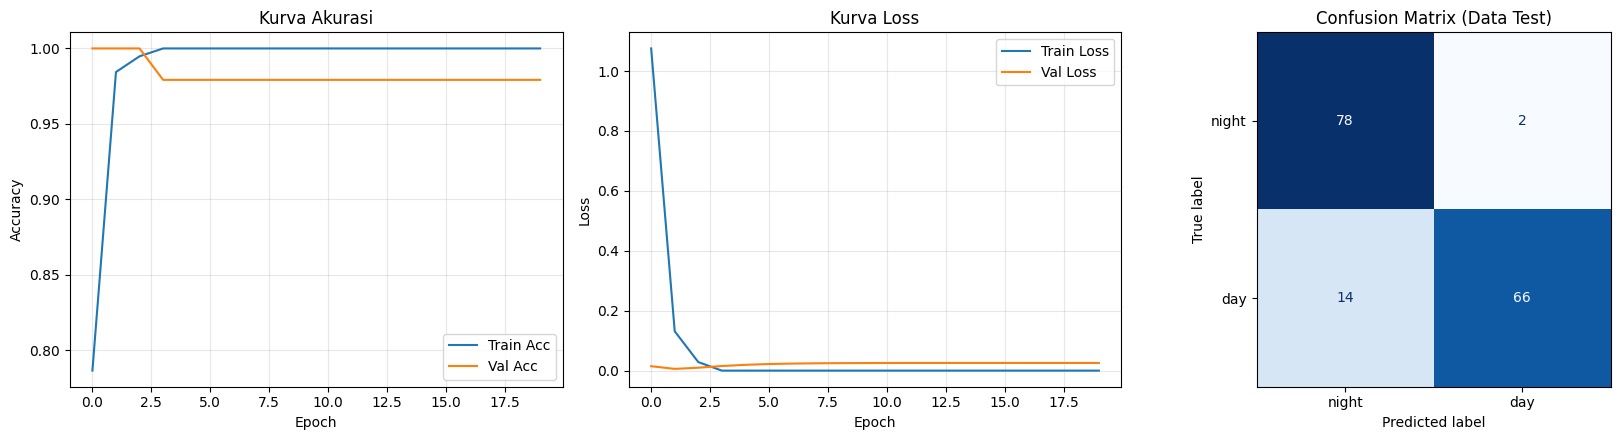

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(history.history['accuracy'], label='Train Acc')
axes[0].plot(history.history['val_accuracy'], label='Val Acc')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy'); axes[0].set_title('Kurva Akurasi')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].set_title('Kurva Loss')
axes[1].legend(); axes[1].grid(alpha=0.3)

ConfusionMatrixDisplay(cm, display_labels=['night', 'day']).plot(ax=axes[2], cmap='Blues', colorbar=False)
axes[2].set_title('Confusion Matrix (Data Test)')

plt.tight_layout()
plt.show()

#### Contoh Hasil Prediksi pada Data Test

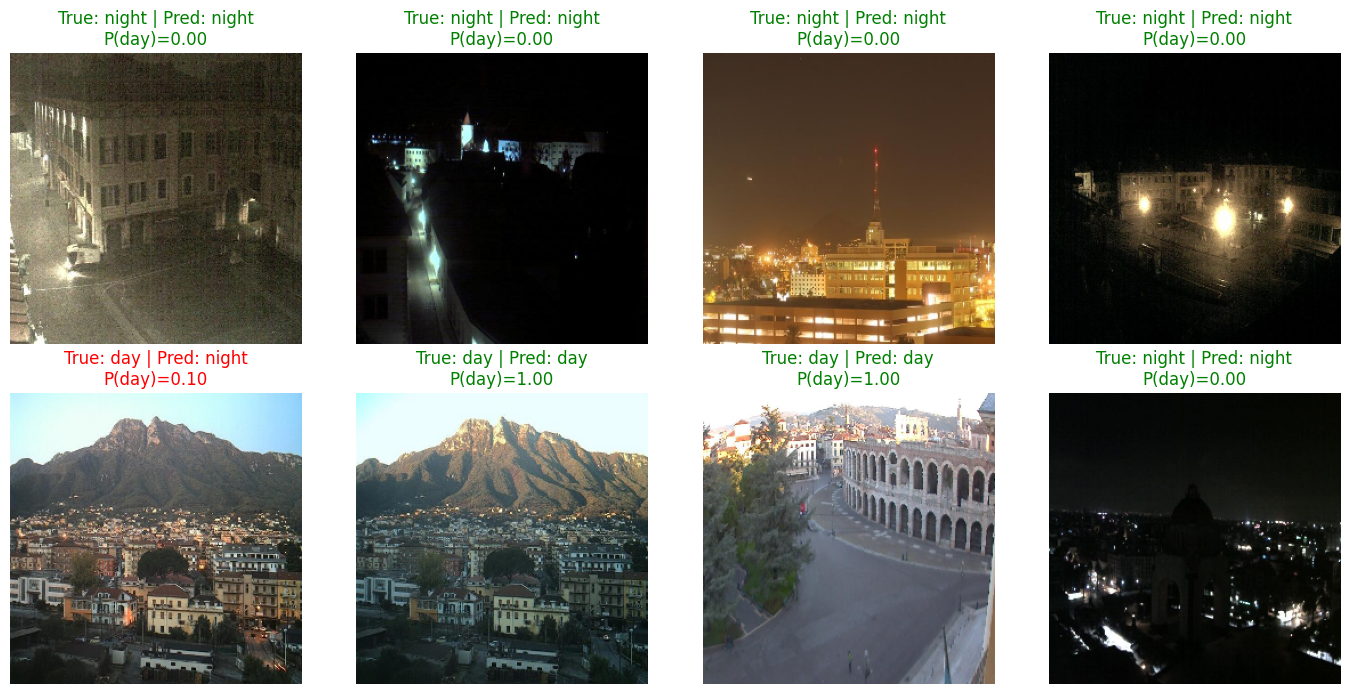

In [15]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(X_test_img), size=8, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.flat, sample_idx):
    pred_lbl = 'day' if y_pred[i] == 1 else 'night'
    true_lbl = 'day' if y_test[i] == 1 else 'night'
    prob = float(y_pred_prob[i][0])
    ax.imshow(X_test_img[i])
    ax.set_title(f"True: {true_lbl} | Pred: {pred_lbl}\nP(day)={prob:.2f}",
                 color='green' if pred_lbl == true_lbl else 'red')
    ax.axis('off')
plt.tight_layout()
plt.show()

### Langkah 12 - Menyimpan Model dan Scaler
Artefak disimpan langsung ke folder `daynight-project/` yang menjadi folder proyek *deployment* Praktikum 2.

> **Catatan:** model disimpan dengan `include_optimizer=False`. Lapisan input berukuran 34.596 fitur membuat model memiliki ±4,4 juta parameter (±17,8 MB). Optimizer Adam menyimpan dua *state* tambahan (momen pertama & kedua) untuk setiap bobot, sehingga jika ikut disimpan ukuran file menjadi ±3× lipat (±53 MB). *State* optimizer hanya diperlukan untuk melanjutkan training, bukan untuk inferensi, jadi aman tidak disimpan dan artefak menjadi lebih ringan untuk di-*upload* ke Hugging Face. Peringatan `model was not compiled` saat memuat ulang model adalah konsekuensi wajar dari opsi ini dan tidak memengaruhi prediksi.

In [16]:
ARTIFACT_DIR = Path('daynight-project')
ARTIFACT_DIR.mkdir(exist_ok=True)

# 1. Simpan Model (format .h5)
model.save(ARTIFACT_DIR / 'day_night_model.h5', include_optimizer=False)
print("Model berhasil disimpan sebagai: day_night_model.h5")

# 2. Simpan Scaler
with open(ARTIFACT_DIR / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler berhasil disimpan sebagai: scaler.pkl")

for f in sorted(ARTIFACT_DIR.glob('*')):
    print(f"  {f.name:22s} {f.stat().st_size / 1e6:8.2f} MB")

Model berhasil disimpan sebagai: day_night_model.h5
Scaler berhasil disimpan sebagai: scaler.pkl
  day_night_model.h5        17.77 MB
  scaler.pkl                 0.83 MB


#### Verifikasi Artefak
Memuat kembali model dan scaler dari file untuk memastikan hasil prediksi identik dengan model di memori. Ini mensimulasikan apa yang akan dilakukan server Flask saat *deployment*.

In [17]:
loaded_model = tf.keras.models.load_model(ARTIFACT_DIR / 'day_night_model.h5')
with open(ARTIFACT_DIR / 'scaler.pkl', 'rb') as f:
    loaded_scaler = pickle.load(f)

prob_loaded = loaded_model.predict(loaded_scaler.transform(X_test_feat), verbose=0)
print(f"Prediksi model hasil load identik: {np.allclose(prob_loaded, y_pred_prob, atol=1e-5)}")
print(f"Akurasi model hasil load         : {((prob_loaded > 0.5).astype(int).ravel() == y_test).mean():.4f}")

Prediksi model hasil load identik: True
Akurasi model hasil load         : 0.9000


### Kesimpulan

1. **Pipeline berjalan end-to-end**: 240 citra training dan 160 citra testing melalui tahap *resize* 256×256 → *grayscale* → HOG (34.596 fitur) → `StandardScaler` → Neural Network 128-64-1.
2. **Performa model**: akurasi pada data test mencapai **90,0%**. Kelas *night* memiliki *recall* 0,97 (78/80 benar), sedangkan kelas *day* memiliki *recall* 0,82 (66/80 benar). Kesalahan didominasi citra siang yang diprediksi malam (14 citra), umumnya citra siang yang mendung/gelap atau memiliki banyak bayangan sehingga pola gradiennya menyerupai citra malam.
3. **Indikasi overfitting**: akurasi training mencapai 100% sejak epoch ke-4 dengan *loss* mendekati nol, sementara *loss* test (1,33) jauh lebih besar dari *loss* validasi. Hal ini wajar karena jumlah fitur (34.596) jauh lebih banyak dibanding jumlah sampel (192). Performa dapat ditingkatkan dengan *dropout*, *early stopping*, menambah data, atau menambahkan fitur warna/kecerahan (misalnya histogram nilai V pada HSV) yang sangat relevan untuk membedakan siang dan malam.
4. **Artefak deployment** `day_night_model.h5` (17,8 MB) dan `scaler.pkl` (0,8 MB) tersimpan di folder `daynight-project/` dan sudah diverifikasi: model hasil *load* menghasilkan prediksi identik dengan model di memori. Artefak ini siap dipakai pada Praktikum 2.